In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from sklearn.model_selection import train_test_split
import seaborn as sns

if (pd is not None and np is not None and plt is not None):
    print("All libraries are imported successfully.")
else:
    print("Error importing libraries.")

All libraries are imported successfully.


In [4]:
# Start gemini , gpt , human dataset
g_data = pd.read_csv('../data/raw/ai_vs_human_text_2026_gpt_gemini.csv')
g_data.head()

,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [11]:
# gpt human data read
gh_data = pd.read_csv('../data/raw/gpt_human_t.csv')
gh_data.head()

,Text,Author,Domain
0,Photo-realistic image rendering using standard...,Human-written,Computer Science and Artificial Intelligence
1,The Large Hadron Collider is exploring physics...,Human-written,Computer Science and Artificial Intelligence
2,With the rapid development of mobile Internet ...,Human-written,Computer Science and Artificial Intelligence
3,Most contour tracking methods can be grouped i...,Human-written,Computer Science and Artificial Intelligence
4,Year 2010 is regarded as the breakthrough year...,Human-written,Computer Science and Artificial Intelligence


In [12]:
gh_data.tail()

,Text,Author,Domain
10816,Urban areas are increasingly experiencing infr...,Mixed text,Social Sciences and Humanities
10817,While it is widely acknowledged that addressin...,Mixed text,Social Sciences and Humanities
10818,With the realisation that stakeholders across ...,Mixed text,Social Sciences and Humanities
10819,"Within this space, established by the non-gove...",Mixed text,Social Sciences and Humanities
10820,"Young onset dementias (YOD), referring to deme...",Mixed text,Social Sciences and Humanities


In [13]:
# Remove mixed text from the dataset
gh_data = gh_data[gh_data['Author'] != 'Mixed text']
gh_data.tail()

,Text,Author,Domain
7209,Urban areas are increasingly experiencing infr...,ChatGPT-generated,Social Sciences and Humanities
7210,While it is widely acknowledged that addressin...,ChatGPT-generated,Social Sciences and Humanities
7211,Educational practitioners and academics have i...,ChatGPT-generated,Social Sciences and Humanities
7212,"Within this space, established by the non-gove...",ChatGPT-generated,Social Sciences and Humanities
7213,"Young onset dementias (YOD), referring to deme...",ChatGPT-generated,Social Sciences and Humanities


In [14]:
# preprocess
gh_data.columns = [c.strip().lower() for c in gh_data.columns]
gh_data['author'] = gh_data['author'].str.strip().str.lower()

# Only valid cases
gh_data = gh_data[gh_data['author'].isin(['chatgpt-generated', 'human-written'])]

gh_data["author"].value_counts()

author
human-written        3607
chatgpt-generated    3607
Name: count, dtype: int64

In [15]:
# Drop empty
before = len(gh_data)
gh_data = gh_data.dropna(subset=['text'])
gh_data = gh_data[gh_data['text'].str.strip() != '']
print(f"Dropped {before - len(gh_data)} rows with empty text.")

Dropped 0 rows with empty text.


In [16]:
before = len(gh_data)
print(f"Before removing duplicates: {before}")
# Remove duplicates
gh_data = gh_data.drop_duplicates(subset=['text'])
print(f"Dropped {before - len(gh_data)} duplicate rows.")

Before removing duplicates: 7214
Dropped 6 duplicate rows.


In [17]:
def clean_text(t):
    t = str(t)
    t = re.sub(r"<.*?>", "", t)  # Remove HTML tags
    t = re.sub(r"http\S+|www\S+"," ", t)  # Remove URLs
    t = re.sub(r"\s+"," ", t) # Collapse whitespace
    return t.strip()

gh_data['text'] = gh_data['text'].apply(clean_text)
gh_data = gh_data[gh_data['text'].str.len() > 0]  # Remove empty text after cleaning

In [19]:
gh_data["word_count"] = gh_data["text"].apply(lambda t: len(t.split()))
gh_data["char_count"] = gh_data["text"].apply(len)

gh_data["word_count"].describe()

count    7208.000000
mean      182.877775
std        58.372178
min        36.000000
25%       142.000000
50%       178.000000
75%       218.000000
max       518.000000
Name: word_count, dtype: float64

In [20]:
# View short and long text lengths
print("Very short:", (gh_data['word_count']< 5).sum())
print("Very long:", (gh_data['word_count']> 2000).sum())

Very short: 0
Very long: 0


In [21]:
if "domain" in gh_data.columns:
    print(gh_data["domain"].value_counts())
    

domain
Computer Science and Artificial Intelligence    1095
Astrophysics and Astronomy                      1093
Genetics and Genomics                            918
Social Sciences and Humanities                   740
Natural Language Processing                      711
Climate Science and Environmental Studies        616
Medical Research and Healthcare                  575
Neuroscience and Psychology                      539
Mathematics and Statistics                       428
Materials science and engineering                398
Materials Science and Engineering                 95
Name: count, dtype: int64


In [22]:
train_df, test_df = train_test_split(gh_data, test_size=0.2, random_state=42, stratify=gh_data['author'])
train_df["split"] = "train"
test_df["split"] = "test"

final_df = pd.concat([train_df, test_df], ignore_index=True)

print("Train:", len(train_df), "| Test:", len(test_df))
train_df["author"].value_counts(normalize=True)

Train: 5766 | Test: 1442


author
chatgpt-generated    0.5
human-written        0.5
Name: proportion, dtype: float64

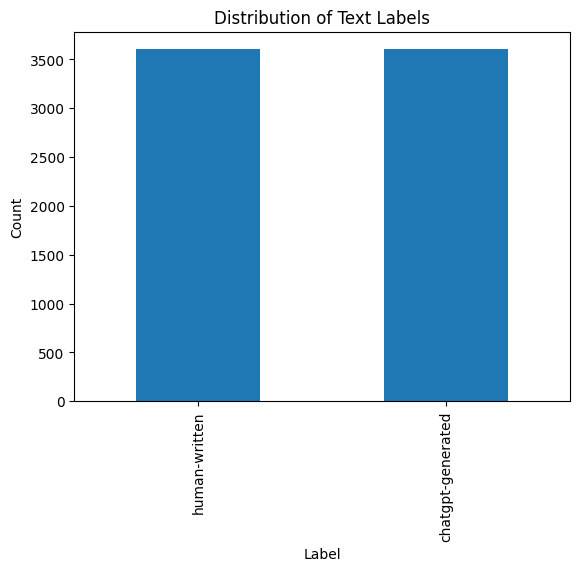

In [26]:
# Visualize the distribution of text lengths
gh_data['author'].value_counts().plot(kind='bar')
plt.title('Distribution of Text Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

In [27]:
os.makedirs(os.path.join("..","data", "processed"), exist_ok=True)
final_df.to_csv(os.path.join("..","data", "processed", "gh_data_processed.csv"), index=False)
print("Processed data saved to ../data/processed/gh_data_processed.csv")


Processed data saved to ../data/processed/gh_data_processed.csv


In [7]:
import pandas as pd

df1 = pd.read_csv("../data_p/processed/gh_data_processed.csv")
df2 = pd.read_csv("../data_p/processed/TXD_22_cleaned.csv")
df3 = pd.read_csv("../data_p/processed/ai_h_cln.csv")

print(df1.head(5))

                                                text author  \
0  Models of cognitive processing typically opera...     ai   
1  An AES is composed of two essential components...  human   
2  To develop an effective Chatbot, researchers a...     ai   
3  In the foreseeable future, wireless sensor net...     ai   
4  All the phenomena of near-ground emissions con...  human   

                                         domain  word_count  char_count  split  
0                   Neuroscience and Psychology         198        1344  train  
1  Computer Science and Artificial Intelligence         299        1925  train  
2  Computer Science and Artificial Intelligence         119         899  train  
3  Computer Science and Artificial Intelligence         195        1551  train  
4     Climate Science and Environmental Studies         388        2415  train  


In [8]:
df2.head()

,Question,text,gen_source,author,split
0,What is an orchard?,A specified plot of land where fruit or nut tr...,ai-generated and ai-refined,ai,train
1,Define planning. What are the steps in the pla...,Setting goals and figuring out the best approa...,ai-generated and ai-refined and human-written,ai,train
2,What is waste management?,Waste management encompasses the entire proces...,gemini,ai,train
3,How does a cycloconverter work?,"In electronics, a cycloconverter is a frequenc...",ai-generated and human-written,ai,train
4,Define reconciliation in post-conflict societies.,Reconciliation in post-conflict societies refe...,copilot,ai,train


In [9]:
df3.head(5)

,text_id,author,gen_source,domain,text,topic_hint,word_count,avg_sentence_length,generation_method,split
0,TXT_0589,human,human,news,Local authorities are responding to reports th...,vaccine distribution challenges,36,9.0,template+human_variation,train
1,TXT_0966,ai,gemini-2.0,social,Spent the morning reading about climate change...,climate change adaptation strategies,28,9.3,style_simulation,train
2,TXT_1383,ai,gpt-4o,news,New developments surrounding election integrit...,election integrity concerns,39,13.0,style_simulation,train
3,TXT_0305,human,human,academic,the relationship between cybersecurity threats...,cybersecurity threats to infrastructure,51,17.0,template+human_variation,train
4,TXT_0099,ai,gemini-2.0,social,Spent the morning reading about aging populati...,aging population challenges,27,9.0,style_simulation,train


In [ ]:
if 'gen_source' not in df1.columns:
    df1['gen_source'] = 'unknown'
if 'domain' not in df2.columns:
    df2['domain'] = 'unknown'

cols = ['text', 'author', 'gen_source', 'domain']
df1 = df1[[c for c in cols if c in df1.columns]]
df2 = df2[[c for c in cols if c in df2.columns]]
df3 = df3[[c for c in cols if c in df3.columns]]

In [11]:
df1["source_dataset"] = "ai_h"
df2["source_dataset"] = "txd_22"
df3["source_dataset"] = "gpt_t2"

In [12]:
combined = pd.concat([df1, df2, df3], ignore_index=True)
print(f"Combined shape: {combined.shape}")

Combined shape: (68174, 5)


In [13]:
before = len(combined)
combined = combined.drop_duplicates(subset=['text'])
print(f"Dropped {before - len(combined)} duplicates")

# class balance
print(combined['author'].value_counts(normalize=True))

# source vs label
print(pd.crosstab(combined['source_dataset'], combined['author']))

# domain vs label
print(pd.crosstab(combined['domain'], combined['author']))

Dropped 36 duplicates
author
ai       0.89464
human    0.10536
Name: proportion, dtype: float64
author             ai  human
source_dataset              
ai_h             3604   3600
gpt_t2            387    579
txd_22          56968   3000
author                                           ai  human
domain                                                    
Astrophysics and Astronomy                      546    547
Climate Science and Environmental Studies       308    308
Computer Science and Artificial Intelligence    547    547
Genetics and Genomics                           459    459
Materials Science and Engineering                48     47
Materials science and engineering               199    199
Mathematics and Statistics                      214    214
Medical Research and Healthcare                 288    284
Natural Language Processing                     355    356
Neuroscience and Psychology                     270    269
Social Sciences and Humanities                  370

In [ ]:
# Balance the dataset by downsampling the majority class
from sklearn.utils import resample

human_df = combined[combined["author"] == "human"]
ai_df = combined[combined["author"] == "ai"]

if len(human_df) != len(ai_df):
    minority_len = min(len(human_df), len(ai_df))
    human_df = resample(human_df, n_samples=minority_len, random_state=42)
    ai_df = resample(ai_df, n_samples=minority_len, random_state=42)
    combined = pd.concat([human_df, ai_df], ignore_index=True)
    print(combined["author"].value_counts())

author
human    7179
ai       7179
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    combined, test_size=0.2, random_state=42, stratify=combined["author"]
)
train_df["split"] = "train"
test_df["split"] = "test"

final = pd.concat([train_df, test_df], ignore_index=True)
final.to_csv("../data_p/processed/final_training_dataset_b.csv", index=False)
print("Saved. Final shape:", final.shape)

Saved. Final shape: (14358, 6)
